# Face Anti-Spoofing Classification — FindIT! DAC 2026
**Team import kalah**

Notebook ini berisi pipeline klasifikasi wajah untuk membedakan orang asli (real person) dari berbagai jenis serangan spoofing. dataset relatif kecil (~1.600 gambar) dengan 6 kelas yang imbalance.

**Pendekatan yang dipakai:**
- EDA mendalam untuk memahami karakteristik tiap kelas spoofing
- ViT-B/16 (Vision Transformer) sebagai backbone — dipilih setelah eksperimen dengan beberapa arsitektur
- Focal Loss + Label Smoothing untuk menangani class imbalance
- MixUp & CutMix sebagai augmentasi tambahan
- Pseudo-labeling pada test set untuk memanfaatkan data unlabeled
- Test-Time Augmentation (TTA) saat inferensi

## 1. Setup Environment

In [ ]:
import os
import warnings
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import seaborn as sns
from pathlib import Path
from tqdm import tqdm

warnings.filterwarnings("ignore")
plt.rcParams["figure.dpi"] = 120

In [ ]:
# Download Dataset
# Menggunakan dataset hasil cleaning manual, hasil cleaning langsungnya terdapat di folder sedangkan link yang dipakai adalah hasil zip
# Data Folder: https://drive.google.com/drive/folders/1oSmdSQPNkJyUVCTVZJkkINvO_CbTeN7B?usp=drive_link
# Data Zip: https://drive.google.com/file/d/1E2sz5dCc7-aISDWg39SIyNW-D2dzuQ3E/view?usp=drive_link
!gdown 1E2sz5dCc7-aISDWg39SIyNW-D2dzuQ3E -O DAC2026.zip
!unzip DAC2026.zip

Downloading...
From (original): https://drive.google.com/uc?id=1E2sz5dCc7-aISDWg39SIyNW-D2dzuQ3E
From (redirected): https://drive.google.com/uc?id=1E2sz5dCc7-aISDWg39SIyNW-D2dzuQ3E&confirm=t&uuid=1b5d6b9e-1452-4e28-b023-91c115cb00e3
To: /kaggle/working/DAC2026.zip
100%|██████████████████████████████████████| 1.26G/1.26G [00:24<00:00, 50.9MB/s]
Archive:  DAC2026.zip
   creating: DAC 2026/
  inflating: DAC 2026/samplesubmission.csv  
   creating: DAC 2026/test/
  inflating: DAC 2026/test/test_001.jpg  
  inflating: DAC 2026/test/test_002.jpg  
  inflating: DAC 2026/test/test_003.jpg  
  inflating: DAC 2026/test/test_004.jpg  
  inflating: DAC 2026/test/test_005.jpg  
  inflating: DAC 2026/test/test_006.jpg  
  inflating: DAC 2026/test/test_007.jpg  
  inflating: DAC 2026/test/test_008.jpg  
  inflating: DAC 2026/test/test_009.jpg  
  inflating: DAC 2026/test/test_010.jpg  
  inflating: DAC 2026/test/test_011.jpg  
  inflating: DAC 2026/test/test_012.jpg  
  inflating: DAC 2026/test/test_

In [ ]:
DATA_ROOT = Path("/kaggle/working/DAC 2026")
OUT_DIR   = Path("/kaggle/working/eda_output")
OUT_DIR.mkdir(parents=True, exist_ok=True)

CLASSES = [
    "realperson", "fake_printed", "fake_screen",
    "fake_mask", "fake_mannequin", "fake_unknown",
]

CLASS_COLORS = {
    "realperson":     "#378ADD",
    "fake_printed":   "#D85A30",
    "fake_screen":    "#D4537E",
    "fake_mask":      "#7F77DD",
    "fake_mannequin": "#1D9E75",
    "fake_unknown":   "#888780",
}

IMG_EXT   = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}
SAMPLE_N  = 200

print(f"Data root : {DATA_ROOT}")
print(f"Output dir: {OUT_DIR}")

Data root : /kaggle/working/DAC 2026
Output dir: /kaggle/working/eda_output


## 2. Exploratory Data Analysis

Sebelum langsung modeling, penting untuk paham dulu datanya seperti apa. Beberapa hal yang perlu dicek:
- Berapa banyak gambar per kelas? Ada imbalance nggak?
- Kualitas gambarnya gimana? (resolusi, blur, brightness)
- Apakah face detector bisa mendeteksi wajah di semua kelas?
- Kelas `fake_unknown` itu isinya apa aja?

In [ ]:
# Katalog semua gambar
records = []

for split in ["train", "test"]:
    split_dir = DATA_ROOT / split
    if not split_dir.exists():
        print(f"  [WARN] Folder tidak ditemukan: {split_dir} — dilewati")
        continue
    for label_dir in split_dir.iterdir():
        if not label_dir.is_dir():
            continue
        label = label_dir.name
        if label not in CLASSES:
            print(f"  [WARN] folder tidak dikenal: {label_dir.name} — dilewati")
            continue
        for img_path in label_dir.rglob("*"):
            if img_path.suffix.lower() not in IMG_EXT:
                continue
            subject_id = None
            for part in img_path.stem.split("_"):
                if part.lower().startswith("subject") or part.lower().startswith("id"):
                    subject_id = part
                    break
            records.append({
                "path":       img_path,
                "label":      label,
                "split":      split,
                "subject_id": subject_id,
                "filename":   img_path.name,
            })

df = pd.DataFrame(records)

print(f"Total gambar: {len(df):,}\n")
print(df.groupby(["split", "label"]).size().unstack(fill_value=0).to_string())

Total gambar: 1,647

label  fake_mannequin  fake_mask  fake_printed  fake_screen  fake_unknown  realperson
split                                                                                
train             215        283           140          198           364         447


### 2.1. Distribusi Kelas

Hal pertama yang dicek — apakah jumlah gambar tiap kelas seimbang? Kalau tidak, nanti perlu penanganan khusus di loss function.



Proporsi per kelas (%):
                train %  test %
label                          
realperson         27.1     NaN
fake_printed        8.5     NaN
fake_screen        12.0     NaN
fake_mask          17.2     NaN
fake_mannequin     13.1     NaN
fake_unknown       22.1     NaN


In [ ]:
train_counts = (df[df["split"] == "train"]["label"]
                .value_counts().reindex(CLASSES, fill_value=0))
test_counts  = (df[df["split"] == "test"]["label"]
                .value_counts().reindex(CLASSES, fill_value=0))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle("Distribusi Kelas", fontsize=14, fontweight="bold")

for ax, (counts, split) in zip(axes, [(train_counts, "train"), (test_counts, "test")]):
    colors = [CLASS_COLORS[c] for c in counts.index]
    bars   = ax.bar(counts.index, counts.values, color=colors,
                    edgecolor="white", linewidth=0.5)
    for bar, val in zip(bars, counts.values):
        ax.text(bar.get_x() + bar.get_width() / 2,
                bar.get_height() + 5, f"{val:,}",
                ha="center", va="bottom", fontsize=9)

    non_zero = counts[counts > 0]
    ratio    = non_zero.max() / non_zero.min() if len(non_zero) > 1 else 1
    status   = "OK" if ratio < 3 else ("Sedang" if ratio < 6 else "PARAH ⚠")

    ax.set_title(f"Split: {split}  (n={counts.sum():,})", fontsize=12)
    ax.set_xlabel(f"Imbalance ratio: {ratio:.1f}×  [{status}]", fontsize=10)
    ax.set_ylabel("Jumlah Sampel")
    ax.tick_params(axis="x", rotation=30)

plt.tight_layout()
plt.savefig(OUT_DIR / "1_class_distribution.png", bbox_inches="tight")
plt.show()

print("Proporsi per kelas (%):")
prop_train = (train_counts / train_counts.sum() * 100).rename("train %")
prop_test  = (test_counts  / test_counts.sum()  * 100).rename("test %")
print(pd.concat([prop_train, prop_test], axis=1).round(1).to_string())

### 2.2. Cek Data Leakage

Penting untuk memastikan tidak ada identitas yang sama di train dan test — kalau ada, evaluasi kita jadi tidak valid.

In [ ]:
if df["subject_id"].isna().all():
    print("[!] Tidak ada subject_id di nama file.")
    print("    Rekomendasi: gunakan face embedding (DeepFace / facenet-pytorch)")
    print("    lalu cluster untuk cek duplikasi identitas antara train dan test.")
else:
    train_subjects = set(df[(df["split"] == "train") & df["subject_id"].notna()]["subject_id"])
    test_subjects  = set(df[(df["split"] == "test")  & df["subject_id"].notna()]["subject_id"])

    leak = train_subjects & test_subjects
    if leak:
        print(f"[BAHAYA] {len(leak)} subject bocor antara train dan test!")
        print(f"  Contoh: {list(leak)[:10]}")
        print("  Solusi: pastikan split dilakukan per subject, bukan per gambar.")
    else:
        print(f"[OK] Tidak ada subject yang sama di train dan test.")
        print(f"     Train: {len(train_subjects)} unique subjects")
        print(f"     Test : {len(test_subjects)} unique subjects")

    print("\nUnique subjects per kelas (train):")
    print(df[df["split"] == "train"].groupby("label")["subject_id"].nunique().to_string())

[!] Tidak ada subject_id di nama file.
    Rekomendasi: gunakan face embedding (DeepFace / facenet-pytorch)
    lalu cluster untuk cek duplikasi identitas antara train dan test.


### 2.3. Kualitas Gambar

Tiap kelas spoofing punya karakteristik visual yang berbeda. Misalnya, foto yang diambil dari layar biasanya lebih gelap dan ada moiré pattern, sementara gambar mannequin cenderung lebih tajam tapi resolusinya bervariasi. Kita cek blur score, brightness, dan resolusi untuk memahami ini.

Computing image stats: 100%|██████████| 1138/1138 [00:43<00:00, 26.19it/s]


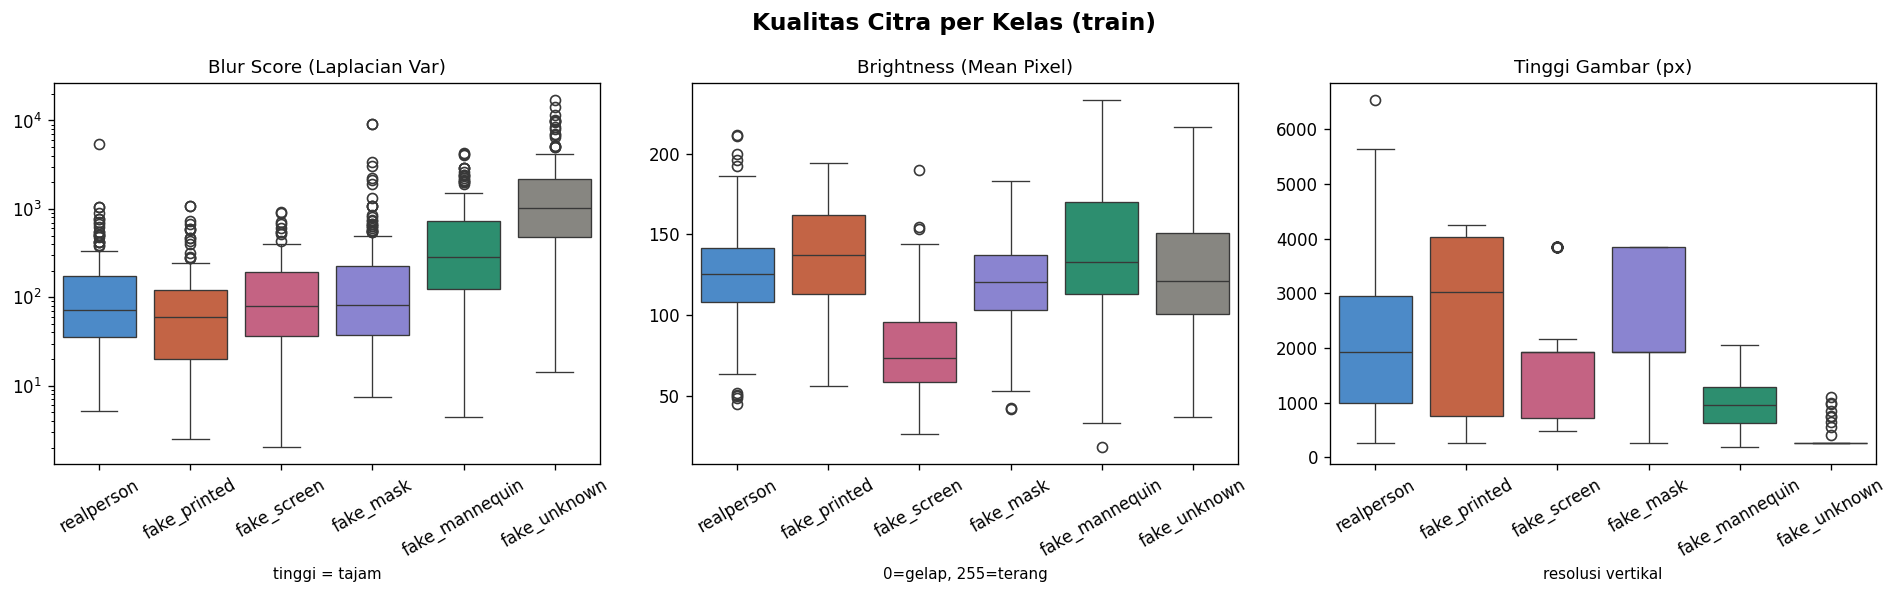


Ringkasan statistik per kelas (train):
                  blur         brightness        height           width        
                  mean     std       mean   std    mean     std    mean     std
label                                                                          
fake_mannequin   575.2   755.5      139.9  40.6   934.3   423.6   772.3   399.4
fake_mask        318.4   990.1      118.0  27.0  2189.6  1102.5  1323.0   589.4
fake_printed     116.6   178.6      136.0  30.8  2472.2  1577.9  1846.6  1272.7
fake_screen      134.4   154.7       78.5  27.7  1634.1   970.6   975.4   512.0
fake_unknown    1840.6  2452.5      125.4  35.9   279.6   117.9   274.6    94.2
realperson       169.0   412.6      125.0  30.3  2016.1  1166.4  1375.4   832.7


In [ ]:
train_df = df[df["split"] == "train"]

sampled_quality = (
    train_df.groupby("label", group_keys=False)
            .apply(lambda x: x.sample(min(len(x), SAMPLE_N), random_state=42))
            .reset_index(drop=True)
)

quality_stats = []

for _, row in tqdm(sampled_quality.iterrows(), total=len(sampled_quality),
                   desc="Computing image stats"):
    img = cv2.imread(str(row["path"]))
    if img is None:
        quality_stats.append({"label": row["label"], "blur": None,
                               "brightness": None, "height": 0, "width": 0,
                               "corrupt": True})
        continue
    h, w   = img.shape[:2]
    gray   = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
    blur   = round(cv2.Laplacian(gray, cv2.CV_64F).var(), 2)
    bright = round(gray.mean(), 2)
    quality_stats.append({"label": row["label"], "blur": blur,
                          "brightness": bright, "height": h, "width": w,
                          "corrupt": False})

stats_df = pd.DataFrame(quality_stats)

corrupt_n = stats_df["corrupt"].sum()
if corrupt_n:
    print(f"[WARN] {corrupt_n} gambar corrupt / tidak bisa dibaca!")

fig, axes = plt.subplots(1, 3, figsize=(16, 5))
fig.suptitle("Kualitas Citra per Kelas (train)", fontsize=14, fontweight="bold")

for ax, (col, title, xlabel) in zip(axes, [
    ("blur",       "Blur Score (Laplacian Var)", "tinggi = tajam"),
    ("brightness", "Brightness (Mean Pixel)",    "0=gelap, 255=terang"),
    ("height",     "Tinggi Gambar (px)",          "resolusi vertikal"),
]):
    clean = stats_df[stats_df[col].notna()]
    order = [c for c in CLASSES if c in clean["label"].unique()]
    sns.boxplot(data=clean, x="label", y=col, order=order,
                palette={c: CLASS_COLORS[c] for c in order},
                ax=ax, linewidth=0.8)
    if col == "blur":
        ax.set_yscale("log")
    ax.set_title(title, fontsize=11)
    ax.set_xlabel(xlabel, fontsize=9)
    ax.set_ylabel("")
    ax.tick_params(axis="x", rotation=30)

plt.tight_layout()
plt.savefig(OUT_DIR / "3_image_quality.png", bbox_inches="tight")
plt.show()

print("\nRingkasan statistik per kelas (train):")
print(stats_df.groupby("label")[["blur", "brightness", "height", "width"]]
              .agg(["mean", "std"]).round(1).to_string())

### 2.4. Face Detection Rate

Kita cek apakah face detector bisa menemukan wajah di setiap gambar. Kalau ada kelas yang detection rate-nya rendah, berarti kita mungkin perlu skip face cropping untuk kelas itu, atau pakai gambar full tanpa crop.

OpenCV DNN face detector siap.


Detecting faces: 100%|██████████| 600/600 [00:27<00:00, 21.74it/s]


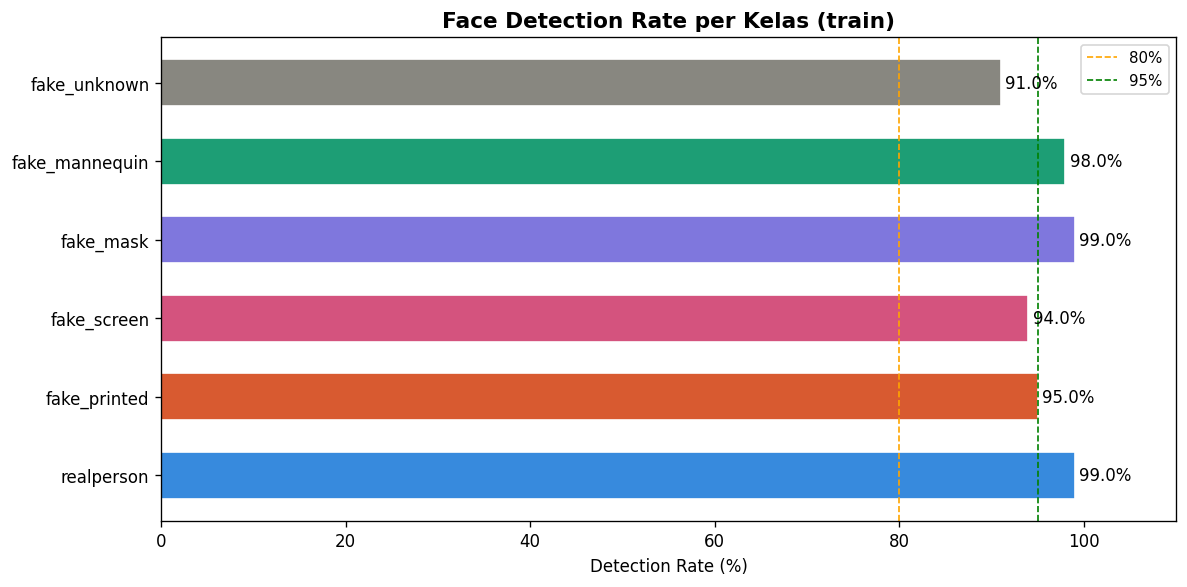

label
realperson        99.0
fake_printed      95.0
fake_screen       94.0
fake_mask         99.0
fake_mannequin    98.0
fake_unknown      91.0


In [ ]:
import urllib.request

# Download model weights jika belum ada
PROTO_URL  = "https://raw.githubusercontent.com/opencv/opencv/master/samples/dnn/face_detector/deploy.prototxt"
MODEL_URL  = "https://github.com/opencv/opencv_3rdparty/raw/dnn_samples_face_detector_20170830/res10_300x300_ssd_iter_140000.caffemodel"
PROTO_PATH = Path("./face_detector.prototxt")
MODEL_PATH = Path("./face_detector.caffemodel")

if not PROTO_PATH.exists():
    print("Downloading prototxt...")
    urllib.request.urlretrieve(PROTO_URL, PROTO_PATH)
if not MODEL_PATH.exists():
    print("Downloading caffemodel (~10MB)...")
    urllib.request.urlretrieve(MODEL_URL, MODEL_PATH)

dnn_detector  = cv2.dnn.readNetFromCaffe(str(PROTO_PATH), str(MODEL_PATH))
CONF_THRESHOLD = 0.5   # minimum confidence untuk dianggap wajah

def detect_faces_dnn(img_bgr, conf_thresh=CONF_THRESHOLD):
    """Return jumlah wajah terdeteksi via OpenCV DNN SSD."""
    h, w = img_bgr.shape[:2]
    blob = cv2.dnn.blobFromImage(
        cv2.resize(img_bgr, (300, 300)), 1.0,
        (300, 300), (104.0, 177.0, 123.0)
    )
    dnn_detector.setInput(blob)
    detections = dnn_detector.forward()
    count = 0
    for i in range(detections.shape[2]):
        if detections[0, 0, i, 2] >= conf_thresh:
            count += 1
    return count

print("OpenCV DNN face detector siap.")

sampled_det = (
    train_df.groupby("label", group_keys=False)
            .apply(lambda x: x.sample(min(len(x), 100), random_state=42))
            .reset_index(drop=True)
)

det_results = []

for _, row in tqdm(sampled_det.iterrows(), total=len(sampled_det),
                   desc="Detecting faces"):
    img = cv2.imread(str(row["path"]))
    if img is None:
        det_results.append({"label": row["label"], "detected": False, "n": 0})
        continue
    n = detect_faces_dnn(img)
    det_results.append({"label": row["label"], "detected": n > 0, "n": n})

det_df   = pd.DataFrame(det_results)
det_rate = (det_df.groupby("label")["detected"].mean() * 100).reindex(CLASSES).fillna(0)

fig, ax = plt.subplots(figsize=(10, 5))
colors  = [CLASS_COLORS.get(c, "#888") for c in det_rate.index]
bars    = ax.barh(det_rate.index, det_rate.values, color=colors,
                  edgecolor="white", height=0.6)
ax.axvline(80, color="orange", linestyle="--", linewidth=1, label="80%")
ax.axvline(95, color="green",  linestyle="--", linewidth=1, label="95%")
for bar, val in zip(bars, det_rate.values):
    ax.text(val + 0.5, bar.get_y() + bar.get_height() / 2,
            f"{val:.1f}%", va="center", fontsize=10)
ax.set_xlim(0, 110)
ax.set_xlabel("Detection Rate (%)")
ax.set_title("Face Detection Rate per Kelas (train)", fontsize=13, fontweight="bold")
ax.legend(fontsize=9)
plt.tight_layout()
plt.savefig(OUT_DIR / "4_face_detection_rate.png", bbox_inches="tight")
plt.show()

print(det_rate.round(1).to_string())

### 2.5. Visualisasi Sampel

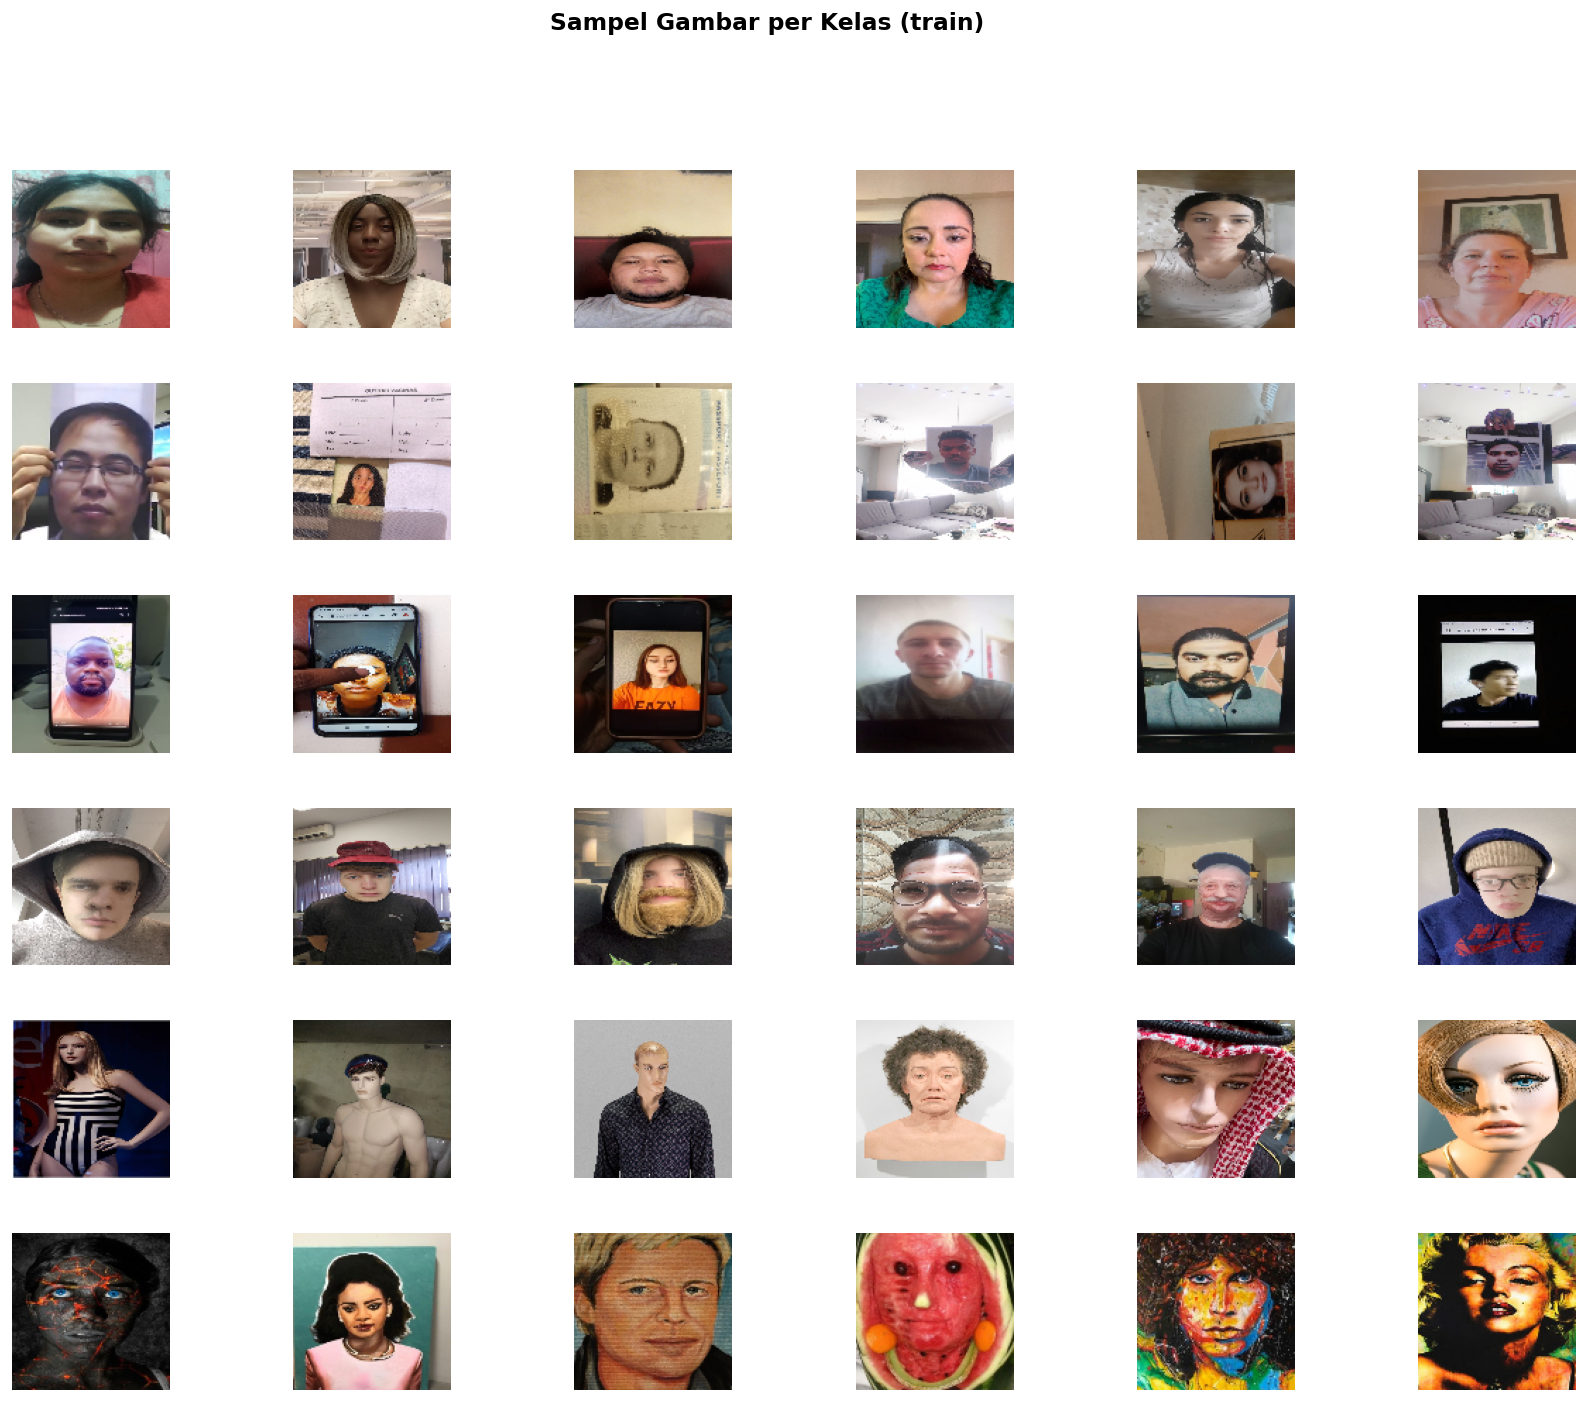

In [ ]:
N_SAMPLES = 6
present   = [c for c in CLASSES if c in train_df["label"].unique()]

fig = plt.figure(figsize=(18, len(present) * 2.2))
fig.suptitle("Sampel Gambar per Kelas (train)", fontsize=14, fontweight="bold")
gs  = gridspec.GridSpec(len(present), N_SAMPLES, figure=fig, hspace=0.35, wspace=0.05)

for row_idx, label in enumerate(present):
    class_df = train_df[train_df["label"] == label]
    samples  = class_df.sample(min(len(class_df), N_SAMPLES), random_state=42)
    for col_idx, (_, srow) in enumerate(samples.iterrows()):
        ax  = fig.add_subplot(gs[row_idx, col_idx])
        img = cv2.imread(str(srow["path"]))
        if img is not None:
            ax.imshow(cv2.cvtColor(cv2.resize(img, (112, 112)), cv2.COLOR_BGR2RGB))
        ax.axis("off")
        if col_idx == 0:
            ax.set_ylabel(label, fontsize=9, rotation=0, ha="right",
                          labelpad=60, color=CLASS_COLORS.get(label, "#333"))

plt.savefig(OUT_DIR / "5a_sample_grid.png", bbox_inches="tight")
plt.show()

### 2.6. Mean Image & Histogram Piksel

Mean image berguna untuk melihat "rata-rata" wajah di tiap kelas. Kalau mean image-nya beda jauh antar kelas, berarti model harusnya cukup mudah membedakan. Histogram piksel juga bisa menunjukkan perbedaan distribusi warna.

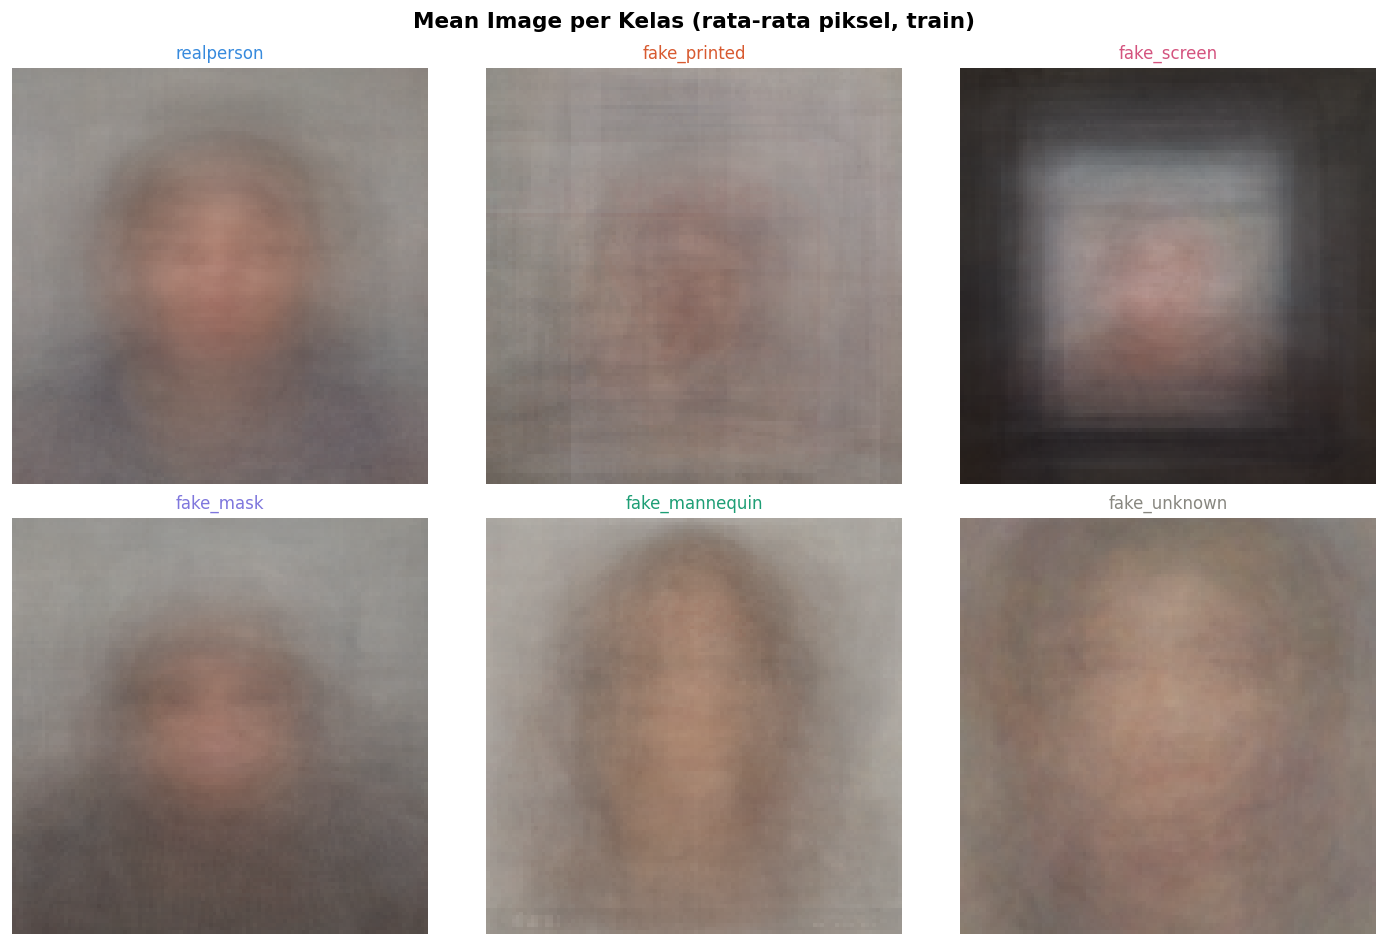

In [ ]:
TARGET_SIZE = (112, 112)

fig, axes = plt.subplots(2, 3, figsize=(12, 8))
fig.suptitle("Mean Image per Kelas (rata-rata piksel, train)", fontsize=13, fontweight="bold")

for ax, label in zip(axes.flat, present):
    class_df = train_df[train_df["label"] == label]
    imgs     = []
    for p in tqdm(class_df["path"].sample(min(len(class_df), 200), random_state=42),
                  desc=label, leave=False):
        img = cv2.imread(str(p))
        if img is not None:
            imgs.append(cv2.resize(img, TARGET_SIZE).astype(np.float32))
    if imgs:
        mean_img = np.mean(imgs, axis=0).astype(np.uint8)
        ax.imshow(cv2.cvtColor(mean_img, cv2.COLOR_BGR2RGB))
    ax.set_title(label, color=CLASS_COLORS.get(label, "#333"), fontsize=10)
    ax.axis("off")

for ax in axes.flat[len(present):]:
    ax.axis("off")

plt.tight_layout()
plt.savefig(OUT_DIR / "5b_mean_images.png", bbox_inches="tight")
plt.show()

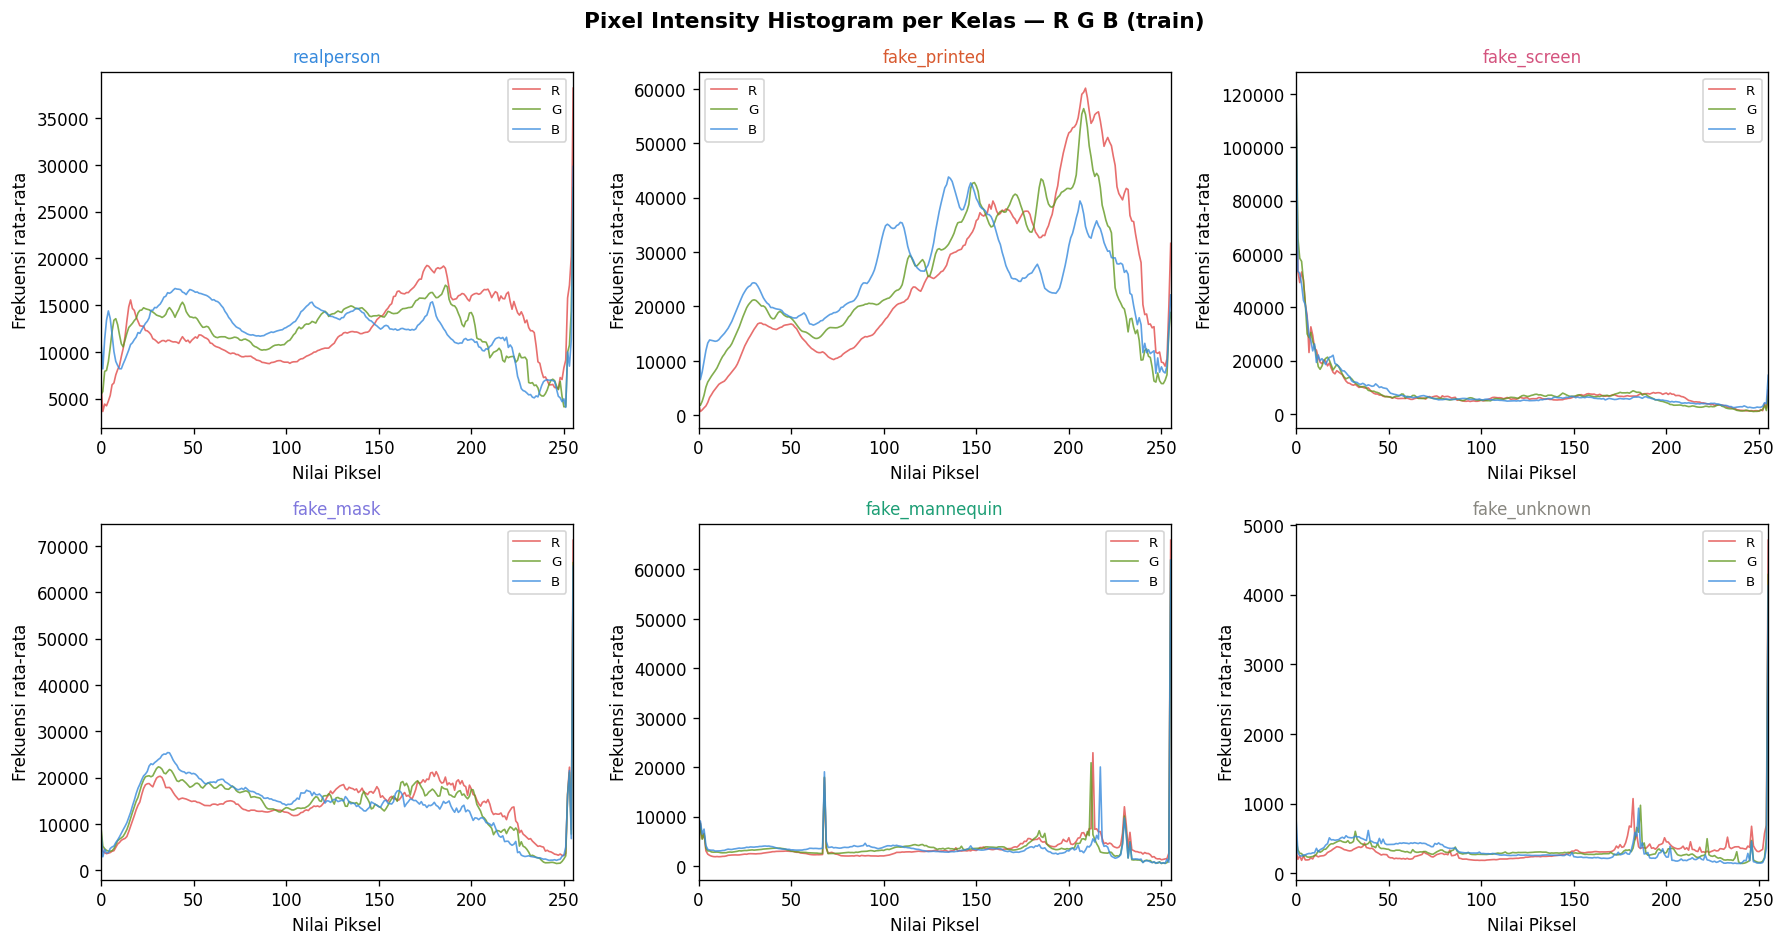

In [ ]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
fig.suptitle("Pixel Intensity Histogram per Kelas — R G B (train)",
             fontsize=13, fontweight="bold")

CH_NAMES  = ["R", "G", "B"]
CH_COLORS = ["#E24B4A", "#639922", "#378ADD"]

for ax, label in zip(axes.flat, present):
    class_df   = train_df[train_df["label"] == label]
    histograms = {0: np.zeros(256), 1: np.zeros(256), 2: np.zeros(256)}
    count      = 0
    for p in class_df["path"].sample(min(len(class_df), 100), random_state=42):
        img = cv2.imread(str(p))
        if img is None:
            continue
        rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
        for ch in range(3):
            histograms[ch] += cv2.calcHist([rgb], [ch], None, [256], [0, 256]).flatten()
        count += 1
    if count:
        for ch in range(3):
            ax.plot(histograms[ch] / count, color=CH_COLORS[ch],
                    label=CH_NAMES[ch], alpha=0.8, linewidth=1)
    ax.set_title(label, color=CLASS_COLORS.get(label, "#333"), fontsize=10)
    ax.set_xlim(0, 255)
    ax.legend(fontsize=8)
    ax.set_xlabel("Nilai Piksel")
    ax.set_ylabel("Frekuensi rata-rata")

for ax in axes.flat[len(present):]:
    ax.axis("off")

plt.tight_layout()
plt.savefig(OUT_DIR / "5c_pixel_histograms.png", bbox_inches="tight")
plt.show()

### 2.7. Clustering `fake_unknown`

Kelas `fake_unknown` menarik karena kemungkinan isinya campuran dari beberapa jenis serangan yang tidak masuk kategori lain. Kita coba cluster berdasarkan histogram warna untuk lihat apakah bisa dikelompokkan.

Extracting color histograms: 100%|██████████| 300/300 [00:00<00:00, 1150.96it/s]


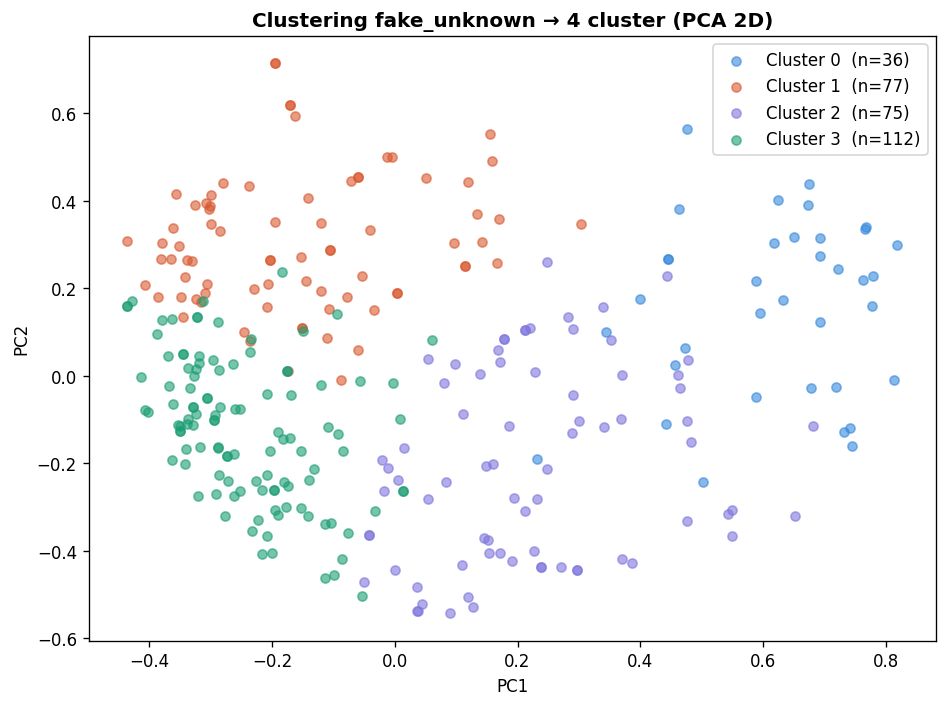

Distribusi cluster: {0: 36, 1: 77, 2: 75, 3: 112}


In [ ]:
from sklearn.cluster import KMeans
from sklearn.preprocessing import normalize
from sklearn.decomposition import PCA

unknown_df = train_df[train_df["label"] == "fake_unknown"]
N_CLUSTERS = 4

features    = []
valid_paths = []

for p in tqdm(unknown_df["path"].sample(min(len(unknown_df), 300), random_state=42),
              desc="Extracting color histograms"):
    img = cv2.imread(str(p))
    if img is None:
        continue
    img_rs = cv2.resize(img, (64, 64))
    hist   = []
    for ch in range(3):
        hist.extend(cv2.calcHist([img_rs], [ch], None, [32], [0, 256]).flatten())
    features.append(hist)
    valid_paths.append(p)

if len(features) >= N_CLUSTERS:
    X      = normalize(np.array(features))
    labels = KMeans(n_clusters=N_CLUSTERS, random_state=42, n_init=10).fit_predict(X)
    X_2d   = PCA(n_components=2, random_state=42).fit_transform(X)

    palette = ["#378ADD", "#D85A30", "#7F77DD", "#1D9E75"]
    fig, ax = plt.subplots(figsize=(8, 6))
    for cl in range(N_CLUSTERS):
        mask = labels == cl
        ax.scatter(X_2d[mask, 0], X_2d[mask, 1],
                   c=palette[cl % len(palette)],
                   label=f"Cluster {cl}  (n={mask.sum()})",
                   alpha=0.6, s=30)
    ax.set_title(f"Clustering fake_unknown → {N_CLUSTERS} cluster (PCA 2D)",
                 fontsize=12, fontweight="bold")
    ax.legend()
    ax.set_xlabel("PC1")
    ax.set_ylabel("PC2")
    plt.tight_layout()
    plt.savefig(OUT_DIR / "5d_unknown_clusters.png", bbox_inches="tight")
    plt.show()
    print("Distribusi cluster:", {i: int((labels == i).sum()) for i in range(N_CLUSTERS)})
else:
    print(f"fake_unknown terlalu sedikit ({len(features)} gambar) untuk clustering.")

### 2.8. Ringkasan EDA

In [ ]:
non_zero = train_counts[train_counts > 0]
ratio    = non_zero.max() / non_zero.min()
status   = "OK" if ratio < 3 else ("Sedang" if ratio < 6 else "PARAH ⚠")

print("=" * 55)
print("  RINGKASAN EDA")
print("=" * 55)
print(f"\nTotal train : {train_counts.sum():,} gambar")
print(f"Total test  : {len(df[df['split'] == 'test']):,} gambar\n")

print("Distribusi train:")
for label, cnt in train_counts.items():
    pct = cnt / train_counts.sum() * 100
    bar = "█" * int(pct / 2)
    print(f"  {label:<18} {cnt:>5,}  ({pct:.1f}%) {bar}")

print(f"\nImbalance ratio: {ratio:.1f}× — {status}")

print("\nKesimpulan:")
print("  • Imbalance ratio 3.2× — perlu Focal Loss + class weights")
print("  • fake_unknown resolusi rendah & heterogen — butuh augmentasi noise")
print("  • fake_screen brightness rendah — augmentasi brightness penting")
print("  • fake_printed paling sedikit (140) — oversampling diperlukan")
print(f"\nPlot tersimpan di: {OUT_DIR.resolve()}")

  RINGKASAN EDA

Total train : 1,647 gambar
Total test  : 0 gambar

Distribusi train:
  realperson           447  (27.1%) █████████████
  fake_printed         140  (8.5%) ████
  fake_screen          198  (12.0%) ██████
  fake_mask            283  (17.2%) ████████
  fake_mannequin       215  (13.1%) ██████
  fake_unknown         364  (22.1%) ███████████

Imbalance ratio: 3.2× — Sedang

Kesimpulan:
  • Imbalance ratio 3.2× — perlu Focal Loss + class weights
  • fake_unknown resolusi rendah & heterogen — butuh augmentasi noise
  • fake_screen brightness rendah — augmentasi brightness penting
  • fake_printed paling sedikit (140) — oversampling diperlukan

Plot tersimpan di: /kaggle/working/eda_output


## 3. Modeling

Berdasarkan temuan EDA di atas, strategi modeling yang dipakai:

1. **Backbone: ViT-B/16** — Vision Transformer yang pretrained di ImageNet-21k. Dipilih karena setelah coba beberapa arsitektur (EfficientNet-B2, ConvNeXtV2), ViT memberikan F1 terbaik di dataset ini. Kemungkinan karena self-attention bisa menangkap pola spoofing yang tersebar di seluruh gambar (bukan cuma lokal).

2. **Focal Loss + Label Smoothing** — Focal Loss supaya model lebih fokus ke sampel yang sulit diklasifikasi, plus class weights untuk menangani imbalance. Label smoothing 0.1 mencegah model terlalu overconfident.

3. **MixUp & CutMix** — Augmentasi ini sangat membantu di dataset kecil. MixUp mencampur dua gambar secara linear, sedangkan CutMix menempel patch dari gambar lain. Keduanya memaksa model belajar fitur yang lebih robust.

4. **Layer-wise LR Decay** — Untuk ViT, layer di dekat input (patch embedding) sudah punya representasi yang bagus dari pretraining, jadi LR-nya dikecilkan. Layer di dekat output (head) butuh LR lebih besar karena perlu adaptasi ke task baru kita.

5. **Pseudo-Labeling** — Setelah training utama selesai, model memprediksi test set. Prediksi dengan confidence tinggi (≥85%) dijadikan label sementara dan dimasukkan ke re-training. Ini semacam semi-supervised learning yang memanfaatkan data unlabeled.

### 3.1. Import & Konfigurasi

In [ ]:
!pip install torch torchvision timm albumentations scikit-learn tqdm pandas opencv-python-headless

import cv2, numpy as np, pandas as pd, torch, torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader, WeightedRandomSampler
import timm, albumentations as A
from albumentations.pytorch import ToTensorV2
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import f1_score, balanced_accuracy_score, classification_report
from sklearn.utils.class_weight import compute_class_weight
from pathlib import Path
from tqdm import tqdm
import warnings, matplotlib.pyplot as plt, seaborn as sns

In [ ]:
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Device: {DEVICE}")

CLASS_TO_IDX = {c: i for i, c in enumerate(CLASSES)}
IDX_TO_CLASS = {i: c for c, i in CLASS_TO_IDX.items()}

IMG_EXT  = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

# Hyperparameter
BACKBONE   = "vit_base_patch16_224"
IMG_SIZE   = 224
BATCH_SIZE = 16
NUM_EPOCHS = 40
LR         = 1e-4
N_FOLDS    = 5
FOLD       = 0
SEED       = 42

LABEL_SMOOTHING = 0.1
MIXUP_ALPHA  = 0.4
CUTMIX_ALPHA = 1.0

torch.manual_seed(SEED)
np.random.seed(SEED)
print(f"Backbone: {BACKBONE}")

Device: cuda
Backbone: vit_base_patch16_224


### 3.2. Persiapan Data

Data di-split menggunakan StratifiedKFold supaya proporsi tiap kelas tetap terjaga di setiap fold. Kita pakai fold ke-0 untuk validasi.

In [ ]:
records = []
for label_dir in (DATA_ROOT / "train").iterdir():
    if not label_dir.is_dir() or label_dir.name not in CLASSES:
        continue
    for p in label_dir.rglob("*"):
        if p.suffix.lower() not in IMG_EXT:
            continue
        subj = None
        for part in p.stem.split("_"):
            if part.lower().startswith("subject") or part.lower().startswith("id"):
                subj = part; break
        if subj is None:
            subj = p.stem.split("_")[0]
        records.append({
            "path":       str(p),
            "label":      label_dir.name,
            "label_idx":  CLASS_TO_IDX[label_dir.name],
            "subject_id": subj,
        })

train_df = pd.DataFrame(records)

skf = StratifiedKFold(n_splits=N_FOLDS, shuffle=True, random_state=SEED)
train_df["fold"] = -1
for fold, (ti, vi) in enumerate(skf.split(train_df, train_df["label_idx"])):
    train_df.loc[vi, "fold"] = fold

fold_train = train_df[train_df["fold"] != FOLD].reset_index(drop=True)
fold_val   = train_df[train_df["fold"] == FOLD].reset_index(drop=True)
print(f"Train: {len(fold_train)} | Val: {len(fold_val)}")
print(fold_val["label"].value_counts().reindex(CLASSES, fill_value=0).to_string())

Train: 1317 | Val: 330
label
realperson        89
fake_printed      28
fake_screen       40
fake_mask         57
fake_mannequin    43
fake_unknown      73


In [ ]:
# Class weights — memberikan bobot lebih tinggi ke kelas minoritas
class_weights = compute_class_weight("balanced", classes=np.arange(len(CLASSES)),
                                     y=fold_train["label_idx"].values)
cw_tensor = torch.tensor(class_weights, dtype=torch.float32).to(DEVICE)
print("Class weights:", {c: round(w, 3) for c, w in zip(CLASSES, class_weights)})

Class weights: {'realperson': np.float64(0.613), 'fake_printed': np.float64(1.96), 'fake_screen': np.float64(1.389), 'fake_mask': np.float64(0.971), 'fake_mannequin': np.float64(1.276), 'fake_unknown': np.float64(0.754)}


### 3.3. Augmentasi

Augmentasi dirancang berdasarkan temuan EDA:
- **ImageCompression** — mensimulasikan artefak JPEG yang sering ada di foto printed/screen
- **GaussNoise & GaussianBlur** — menambah robustness terhadap variasi kualitas gambar
- **CoarseDropout** — mirip Cutout, memaksa model tidak bergantung pada satu area saja
- **ShiftScaleRotate** — variasi geometri dasar

In [ ]:
MEAN, STD = [0.485,0.456,0.406], [0.229,0.224,0.225]

train_tfm = A.Compose([
    A.Resize(IMG_SIZE, IMG_SIZE),
    A.HorizontalFlip(p=0.5),
    A.RandomBrightnessContrast(0.25, 0.25, p=0.6),
    A.HueSaturationValue(10, 25, 15, p=0.5),
    A.GaussianBlur(blur_limit=(3,7), p=0.3),
    A.ImageCompression(quality_lower=50, quality_upper=95, p=0.6),
    A.GaussNoise(var_limit=(5,30), p=0.3),
    A.ShiftScaleRotate(0.05, 0.15, 15, border_mode=cv2.BORDER_REFLECT, p=0.5),
    A.CoarseDropout(max_holes=6, max_height=24, max_width=24, p=0.3),
    A.Normalize(mean=MEAN, std=STD),
    ToTensorV2(),
])

val_tfm = A.Compose([
    A.Resize(IMG_SIZE, IMG_SIZE),
    A.Normalize(mean=MEAN, std=STD),
    ToTensorV2(),
])

### 3.4. Dataset & DataLoader

Dataset class yang juga mendukung MixUp dan CutMix. Kedua teknik ini diterapkan di level batch (bukan per gambar) supaya lebih efisien.

- **MixUp**: `img = λ·img_a + (1-λ)·img_b`, label juga di-mix
- **CutMix**: tempel patch persegi dari gambar lain ke gambar utama

Kita juga pakai `WeightedRandomSampler` supaya kelas minoritas seperti `fake_printed` lebih sering muncul di training.

In [ ]:
class FaceDataset(Dataset):
    def __init__(self, df, transform=None):
        self.df, self.transform = df.reset_index(drop=True), transform
    def __len__(self): return len(self.df)
    def __getitem__(self, idx):
        row = self.df.iloc[idx]
        img = cv2.cvtColor(cv2.imread(row["path"]), cv2.COLOR_BGR2RGB)
        if self.transform:
            img = self.transform(image=img)["image"]
        return img, row["label_idx"]


def mixup_batch(imgs, labels, alpha=0.4):
    lam   = np.random.beta(alpha, alpha)
    idx   = torch.randperm(imgs.size(0))
    mixed = lam * imgs + (1 - lam) * imgs[idx]
    return mixed, labels, labels[idx], lam


def cutmix_batch(imgs, labels, alpha=1.0):
    lam   = np.random.beta(alpha, alpha)
    idx   = torch.randperm(imgs.size(0))
    _, _, H, W = imgs.shape
    cut_rat = np.sqrt(1 - lam)
    cut_w, cut_h = int(W * cut_rat), int(H * cut_rat)
    cx, cy = np.random.randint(W), np.random.randint(H)
    x1, x2 = max(cx - cut_w//2, 0), min(cx + cut_w//2, W)
    y1, y2 = max(cy - cut_h//2, 0), min(cy + cut_h//2, H)
    mixed        = imgs.clone()
    mixed[:, :, y1:y2, x1:x2] = imgs[idx, :, y1:y2, x1:x2]
    lam = 1 - (x2-x1)*(y2-y1) / (W*H)
    return mixed, labels, labels[idx], lam


sample_weights = [class_weights[l] for l in fold_train["label_idx"]]
sampler = WeightedRandomSampler(sample_weights, len(fold_train), replacement=True)

train_ds     = FaceDataset(fold_train, train_tfm)
val_ds       = FaceDataset(fold_val,   val_tfm)
train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, sampler=sampler,
                          num_workers=2, pin_memory=True)
val_loader   = DataLoader(val_ds,   batch_size=BATCH_SIZE, shuffle=False,
                          num_workers=2, pin_memory=True)
print(f"Train batches: {len(train_loader)} | Val batches: {len(val_loader)}")

Train batches: 83 | Val batches: 21


### 3.5. Model — ViT-B/16

Vision Transformer pretrained di ImageNet-21k. Model ini punya 85.8M parameter — cukup besar untuk dataset kecil kita, tapi dengan augmentasi dan regularisasi yang tepat, ternyata hasilnya jauh lebih baik dibanding CNN yang lebih kecil.

In [ ]:
model = timm.create_model(BACKBONE, pretrained=True, num_classes=len(CLASSES))
model = model.to(DEVICE)

total  = sum(p.numel() for p in model.parameters())
print(f"Backbone  : {BACKBONE}")
print(f"Params    : {total/1e6:.1f}M")

model.safetensors:   0%|          | 0.00/346M [00:00<?, ?B/s]

Backbone  : vit_base_patch16_224
Params    : 85.8M


### 3.6. Loss Function

Focal Loss mengurangi kontribusi sampel yang sudah mudah diklasifikasi, sehingga model lebih fokus belajar dari sampel yang sulit. Dikombinasikan dengan label smoothing supaya model tidak terlalu yakin pada satu kelas — ini membantu generalisasi.

In [ ]:
class FocalLossLS(nn.Module):
    """Focal Loss + Label Smoothing"""
    def __init__(self, gamma=2.0, weight=None, smoothing=0.1):
        super().__init__()
        self.gamma, self.weight, self.smoothing = gamma, weight, smoothing

    def forward(self, logits, targets):
        n_cls = logits.size(1)
        with torch.no_grad():
            soft = torch.full_like(logits, self.smoothing / (n_cls - 1))
            soft.scatter_(1, targets.unsqueeze(1), 1.0 - self.smoothing)
        log_p  = F.log_softmax(logits, dim=1)
        ce     = -(soft * log_p).sum(dim=1)
        if self.weight is not None:
            ce = ce * self.weight[targets]
        pt     = torch.exp(-ce)
        focal  = ((1 - pt) ** self.gamma) * ce
        return focal.mean()


def mixup_loss(criterion, logits, lam, labels_a, labels_b):
    return lam * criterion(logits, labels_a) + (1 - lam) * criterion(logits, labels_b)


criterion = FocalLossLS(gamma=2.0, weight=cw_tensor, smoothing=LABEL_SMOOTHING)
print(f"Loss: FocalLoss(gamma=2) + LabelSmoothing({LABEL_SMOOTHING})")

Loss: FocalLoss(gamma=2) + LabelSmoothing(0.1)


### 3.7. Optimizer — Layer-wise LR Decay

Untuk ViT, teknik ini cukup penting. Idenya: layer yang dekat input sudah belajar fitur general dari ImageNet pretraining, jadi LR-nya kecil aja supaya tidak "lupa". Sementara layer yang dekat output perlu LR lebih besar untuk beradaptasi ke task anti-spoofing kita.

In [ ]:
WARMUP_EPOCHS = 5
LR_DECAY      = 0.75

param_groups = []
if hasattr(model, "blocks"):
    n_layers  = len(model.blocks)
    decay_map = {}
    decay_map["patch_embed"] = LR_DECAY ** (n_layers + 1)
    for i, _ in enumerate(model.blocks):
        decay_map[f"blocks.{i}"] = LR_DECAY ** (n_layers - i)
    decay_map["norm"]  = LR_DECAY ** 0
    decay_map["head"]  = 1.0

    for name, param in model.named_parameters():
        lr_scale = 1.0
        for key, scale in decay_map.items():
            if name.startswith(key):
                lr_scale = scale; break
        param_groups.append({"params": [param], "lr": LR * lr_scale})
else:
    head_params     = list(model.classifier.parameters()) \
                      if hasattr(model, "classifier") else list(model.head.parameters())
    backbone_params = [p for p in model.parameters()
                       if not any(p is h for h in head_params)]
    param_groups = [
        {"params": backbone_params, "lr": LR / 10},
        {"params": head_params,     "lr": LR},
    ]

optimizer = torch.optim.AdamW(param_groups, weight_decay=1e-4)
scheduler = torch.optim.lr_scheduler.CosineAnnealingWarmRestarts(
    optimizer, T_0=NUM_EPOCHS, T_mult=1, eta_min=1e-7
)
print(f"Optimizer: AdamW + Layer-wise LR decay ({LR_DECAY})")
print(f"Scheduler: CosineAnnealingWarmRestarts")

Optimizer: AdamW + Layer-wise LR decay (0.75)
Scheduler: CosineAnnealingWarmRestarts


### 3.8. Training

Training loop 40 epoch dengan MixUp/CutMix yang diterapkan secara random (50% chance setiap batch). Model terbaik disimpan berdasarkan val F1-Macro.

In [ ]:
USE_MIXUP  = MIXUP_ALPHA  > 0
USE_CUTMIX = CUTMIX_ALPHA > 0

best_f1, history = 0.0, []

for epoch in range(1, NUM_EPOCHS + 1):

    # ── Train ──
    model.train()
    tr_loss, tr_preds, tr_labels = 0.0, [], []

    for imgs, labels in tqdm(train_loader, desc=f"E{epoch:02d} train", leave=False):
        imgs, labels = imgs.to(DEVICE), labels.to(DEVICE)

        use_mix = (USE_MIXUP or USE_CUTMIX) and np.random.rand() < 0.5
        if use_mix:
            if USE_CUTMIX and (not USE_MIXUP or np.random.rand() < 0.5):
                imgs, la, lb, lam = cutmix_batch(imgs, labels, CUTMIX_ALPHA)
            else:
                imgs, la, lb, lam = mixup_batch(imgs, labels, MIXUP_ALPHA)
            logits = model(imgs)
            loss   = mixup_loss(criterion, logits, lam, la, lb)
        else:
            logits = model(imgs)
            loss   = criterion(logits, labels)

        optimizer.zero_grad()
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        optimizer.step()

        tr_loss  += loss.item() * len(imgs)
        tr_preds.extend(logits.argmax(1).cpu().numpy())
        tr_labels.extend(labels.cpu().numpy())

    scheduler.step()

    # ── Val ──
    model.eval()
    vl_loss, vl_preds, vl_labels = 0.0, [], []

    with torch.no_grad():
        for imgs, labels in tqdm(val_loader, desc=f"E{epoch:02d} val  ", leave=False):
            imgs, labels = imgs.to(DEVICE), labels.to(DEVICE)
            logits = model(imgs)
            vl_loss += criterion(logits, labels).item() * len(imgs)
            vl_preds.extend(logits.argmax(1).cpu().numpy())
            vl_labels.extend(labels.cpu().numpy())

    tr_f1 = f1_score(tr_labels, tr_preds, average="macro", zero_division=0)
    vl_f1 = f1_score(vl_labels, vl_preds, average="macro", zero_division=0)
    tr_ba = balanced_accuracy_score(tr_labels, tr_preds)
    vl_ba = balanced_accuracy_score(vl_labels, vl_preds)

    history.append({"epoch": epoch,
                    "tr_loss": tr_loss/len(train_ds), "vl_loss": vl_loss/len(val_ds),
                    "tr_f1": tr_f1, "vl_f1": vl_f1,
                    "tr_ba": tr_ba, "vl_ba": vl_ba})

    if vl_f1 > best_f1:
        best_f1 = vl_f1
        torch.save(model.state_dict(), OUT_DIR / f"best_{BACKBONE.replace('/','-')}.pth")
        flag = " ← best"
    else:
        flag = ""

    print(f"Ep {epoch:02d}/{NUM_EPOCHS} | "
          f"loss {tr_loss/len(train_ds):.4f}/{vl_loss/len(val_ds):.4f} | "
          f"F1 {tr_f1:.4f}/{vl_f1:.4f} | "
          f"BA {tr_ba:.4f}/{vl_ba:.4f}{flag}")

print(f"\nBest val F1: {best_f1:.4f}")

Ep 01/40 | loss 0.7850/0.2870 | F1 0.6084/0.8872 | BA 0.6153/0.8992 ← best


Ep 02/40 | loss 0.5317/0.2592 | F1 0.7636/0.8849 | BA 0.7689/0.9050


Ep 03/40 | loss 0.4591/0.1779 | F1 0.7845/0.9364 | BA 0.7834/0.9452 ← best


Ep 04/40 | loss 0.4206/0.1977 | F1 0.8349/0.9288 | BA 0.8365/0.9379


Ep 05/40 | loss 0.3846/0.1676 | F1 0.8137/0.9435 | BA 0.8124/0.9518 ← best


Ep 06/40 | loss 0.3816/0.1610 | F1 0.8218/0.9516 | BA 0.8230/0.9580 ← best


Ep 07/40 | loss 0.3061/0.1532 | F1 0.8921/0.9573 | BA 0.8919/0.9614 ← best


Ep 08/40 | loss 0.3264/0.1433 | F1 0.8583/0.9621 | BA 0.8595/0.9660 ← best


Ep 09/40 | loss 0.3193/0.1359 | F1 0.8097/0.9709 | BA 0.8108/0.9741 ← best


Ep 10/40 | loss 0.3013/0.1494 | F1 0.8591/0.9580 | BA 0.8600/0.9567


Ep 11/40 | loss 0.3213/0.1342 | F1 0.8694/0.9739 | BA 0.8689/0.9759 ← best


Ep 12/40 | loss 0.3386/0.1311 | F1 0.7900/0.9674 | BA 0.7923/0.9723


Ep 13/40 | loss 0.2972/0.1460 | F1 0.8231/0.9666 | BA 0.8241/0.9677


Ep 14/40 | loss 0.2948/0.1397 | F1 0.8370/0.9656 | BA 0.8371/0.9730


Ep 15/40 | loss 0.3253/0.1206 | F1 0.8042/0.9734 | BA 0.8051/0.9785


Ep 16/40 | loss 0.3151/0.1240 | F1 0.8425/0.9713 | BA 0.8427/0.9744


Ep 17/40 | loss 0.3411/0.1386 | F1 0.8535/0.9721 | BA 0.8540/0.9724


Ep 18/40 | loss 0.2675/0.1430 | F1 0.8584/0.9604 | BA 0.8565/0.9629


Ep 19/40 | loss 0.2853/0.1500 | F1 0.8680/0.9698 | BA 0.8680/0.9717


Ep 20/40 | loss 0.3264/0.1401 | F1 0.8173/0.9728 | BA 0.8176/0.9740


Ep 21/40 | loss 0.3069/0.1494 | F1 0.8490/0.9736 | BA 0.8510/0.9719


Ep 22/40 | loss 0.3207/0.1405 | F1 0.7974/0.9712 | BA 0.7967/0.9701


Ep 23/40 | loss 0.2497/0.1504 | F1 0.8643/0.9712 | BA 0.8665/0.9701


Ep 24/40 | loss 0.2651/0.1492 | F1 0.8521/0.9677 | BA 0.8535/0.9672


Ep 25/40 | loss 0.2931/0.1511 | F1 0.8954/0.9647 | BA 0.8952/0.9649


Ep 26/40 | loss 0.3013/0.1406 | F1 0.7847/0.9702 | BA 0.7837/0.9701


Ep 27/40 | loss 0.2774/0.1499 | F1 0.8767/0.9736 | BA 0.8789/0.9730


Ep 28/40 | loss 0.2599/0.1402 | F1 0.8334/0.9677 | BA 0.8319/0.9672


Ep 29/40 | loss 0.2791/0.1473 | F1 0.8247/0.9712 | BA 0.8250/0.9701


Ep 30/40 | loss 0.3034/0.1413 | F1 0.8217/0.9712 | BA 0.8253/0.9701


Ep 31/40 | loss 0.2883/0.1422 | F1 0.8458/0.9736 | BA 0.8460/0.9730


Ep 32/40 | loss 0.2495/0.1490 | F1 0.9044/0.9712 | BA 0.9054/0.9701


Ep 33/40 | loss 0.2624/0.1524 | F1 0.8451/0.9712 | BA 0.8460/0.9701


Ep 34/40 | loss 0.2659/0.1495 | F1 0.8236/0.9712 | BA 0.8247/0.9701


Ep 35/40 | loss 0.2798/0.1491 | F1 0.8546/0.9712 | BA 0.8545/0.9701


Ep 36/40 | loss 0.2646/0.1477 | F1 0.8309/0.9712 | BA 0.8324/0.9701


Ep 37/40 | loss 0.2713/0.1479 | F1 0.8682/0.9712 | BA 0.8691/0.9701


Ep 38/40 | loss 0.2573/0.1481 | F1 0.8611/0.9712 | BA 0.8616/0.9701


Ep 39/40 | loss 0.2601/0.1486 | F1 0.8319/0.9712 | BA 0.8321/0.9701


Ep 40/40 | loss 0.2660/0.1478 | F1 0.9070/0.9712 | BA 0.9068/0.9701

Best val F1: 0.9739


### 3.9. Pseudo-Labeling

Teknik ini memanfaatkan test set yang unlabeled. Idenya sederhana:
1. Pakai model terbaik untuk memprediksi test set
2. Ambil hanya prediksi dengan confidence tinggi (softmax ≥ 0.85)
3. Jadikan prediksi ini sebagai "label sementara"
4. Masukkan ke training data dan fine-tune model dengan LR yang dikecilkan

Ini membantu karena model mendapat lebih banyak data untuk belajar, terutama untuk kelas yang sampelnya sedikit. Risikonya: kalau banyak pseudo label yang salah, model bisa makin buruk. Makanya kita pakai threshold tinggi (0.85) supaya hanya sampel yang benar-benar yakin yang dipakai.

In [ ]:
PSEUDO_THRESHOLD = 0.85
PSEUDO_EPOCHS    = 10

test_dir   = DATA_ROOT / "test"
test_files = sorted([p for p in test_dir.rglob("*") if p.suffix.lower() in IMG_EXT])

if not test_files:
    print("[!] Tidak ada file di test dir. Skip pseudo-labeling.")
else:
    model.load_state_dict(torch.load(OUT_DIR / f"best_{BACKBONE.replace('/','-')}.pth",
                                     map_location=DEVICE))
    model.eval()

    test_records = [{"path": str(p), "label": "realperson",
                     "label_idx": 0, "subject_id": "test"} for p in test_files]
    test_df_raw  = pd.DataFrame(test_records)
    test_ds_raw  = FaceDataset(test_df_raw, val_tfm)
    test_loader  = DataLoader(test_ds_raw, batch_size=BATCH_SIZE,
                              shuffle=False, num_workers=2)

    all_probs = []
    with torch.no_grad():
        for imgs, _ in tqdm(test_loader, desc="Pseudo predict"):
            probs = F.softmax(model(imgs.to(DEVICE)), dim=1).cpu().numpy()
            all_probs.append(probs)
    all_probs = np.vstack(all_probs)

    max_probs  = all_probs.max(axis=1)
    pseudo_idx = np.where(max_probs >= PSEUDO_THRESHOLD)[0]
    print(f"\nTest total : {len(test_files)}")
    print(f"Confident  : {len(pseudo_idx)} (>= {PSEUDO_THRESHOLD})")

    if len(pseudo_idx) > 10:
        pseudo_labels = all_probs[pseudo_idx].argmax(axis=1)
        pseudo_records = [{
            "path":       str(test_files[i]),
            "label":      IDX_TO_CLASS[pseudo_labels[j]],
            "label_idx":  int(pseudo_labels[j]),
            "subject_id": "pseudo",
            "fold":       -1,
        } for j, i in enumerate(pseudo_idx)]
        pseudo_df = pd.DataFrame(pseudo_records)

        print("\nDistribusi pseudo labels:")
        print(pseudo_df["label"].value_counts().to_string())

        augmented_train = pd.concat([fold_train, pseudo_df], ignore_index=True)
        pseudo_weights  = [class_weights[l] for l in augmented_train["label_idx"]]
        pseudo_sampler  = WeightedRandomSampler(pseudo_weights, len(augmented_train),
                                                replacement=True)
        pseudo_loader   = DataLoader(FaceDataset(augmented_train, train_tfm),
                                     batch_size=BATCH_SIZE, sampler=pseudo_sampler,
                                     num_workers=2, pin_memory=True)

        for g in optimizer.param_groups:
            g["lr"] = g["lr"] * 0.1

        for epoch in range(1, PSEUDO_EPOCHS + 1):
            model.train()
            for imgs, labels in tqdm(pseudo_loader,
                                     desc=f"Pseudo E{epoch:02d}", leave=False):
                imgs, labels = imgs.to(DEVICE), labels.to(DEVICE)
                logits = model(imgs)
                loss   = criterion(logits, labels)
                optimizer.zero_grad(); loss.backward()
                torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
                optimizer.step()

            model.eval()
            vl_preds, vl_labels_ep = [], []
            with torch.no_grad():
                for imgs, labels in val_loader:
                    logits = model(imgs.to(DEVICE))
                    vl_preds.extend(logits.argmax(1).cpu().numpy())
                    vl_labels_ep.extend(labels.numpy())
            vl_f1 = f1_score(vl_labels_ep, vl_preds, average="macro", zero_division=0)

            if vl_f1 > best_f1:
                best_f1 = vl_f1
                torch.save(model.state_dict(),
                           OUT_DIR / f"best_{BACKBONE.replace('/','-')}.pth")
                flag = " ← best"
            else:
                flag = ""
            print(f"Pseudo E{epoch:02d} | val F1: {vl_f1:.4f}{flag}")
    else:
        print("Sampel confident terlalu sedikit, skip pseudo-labeling.")

Pseudo predict: 100%|██████████| 26/26 [00:06<00:00,  3.92it/s]



Test total : 404
Confident  : 254 (>= 0.85)

Distribusi pseudo labels:
label
fake_printed      50
fake_screen       49
realperson        48
fake_unknown      42
fake_mannequin    36
fake_mask         29


Pseudo E01 | val F1: 0.9803 ← best


Pseudo E02 | val F1: 0.9829 ← best


Pseudo E03 | val F1: 0.9734


Pseudo E04 | val F1: 0.9757


Pseudo E05 | val F1: 0.9798


Pseudo E06 | val F1: 0.9805


Pseudo E07 | val F1: 0.9715


Pseudo E08 | val F1: 0.9805


Pseudo E09 | val F1: 0.9774


Pseudo E10 | val F1: 0.9781


## 4. Submission

Untuk submission final, kita pakai Test-Time Augmentation (TTA) — gambar test di-augmentasi beberapa kali (flip, sedikit brightness change, kompresi), lalu probabilitas dari semua versi dirata-ratakan. Ini biasanya memberikan sedikit peningkatan dibanding prediksi single pass.

In [ ]:
test_dir   = DATA_ROOT / "test"
test_files = sorted([p for p in test_dir.rglob("*") if p.suffix.lower() in IMG_EXT])

if not test_files:
    print("[!] Tidak ada file di test dir.")
else:
    test_records = [{"path": str(p), "label": "realperson",
                     "label_idx": 0, "subject_id": "test"} for p in test_files]

    # Load model terbaik
    model.load_state_dict(torch.load(OUT_DIR / f"best_{BACKBONE.replace('/','-')}.pth",
                                     map_location=DEVICE))
    model.eval()

    # TTA — 5 kali forward pass dengan augmentasi ringan
    TTA_N   = 5
    tta_tfm = A.Compose([
        A.Resize(IMG_SIZE, IMG_SIZE),
        A.HorizontalFlip(p=0.5),
        A.RandomBrightnessContrast(0.1, 0.1, p=0.4),
        A.ImageCompression(quality_lower=75, quality_upper=100, p=0.3),
        A.Normalize(mean=MEAN, std=STD),
        ToTensorV2(),
    ])

    final_probs = np.zeros((len(test_files), len(CLASSES)))

    for tta_i in range(TTA_N):
        tta_ds  = FaceDataset(pd.DataFrame(test_records), tta_tfm)
        tta_ldr = DataLoader(tta_ds, batch_size=BATCH_SIZE,
                             shuffle=False, num_workers=2)
        batch_p = []
        with torch.no_grad():
            for imgs, _ in tqdm(tta_ldr, desc=f"TTA {tta_i+1}/{TTA_N}", leave=False):
                batch_p.append(F.softmax(model(imgs.to(DEVICE)), dim=1).cpu().numpy())
        final_probs += np.vstack(batch_p)

    final_probs /= TTA_N
    final_preds = final_probs.argmax(axis=1)

    submission = pd.DataFrame({
        "id":  [p.stem for p in test_files],
        "label":     [IDX_TO_CLASS[p] for p in final_preds],
    })

    path = OUT_DIR / "submission.csv"
    submission.to_csv(path, index=False)
    print(f"\nSubmission tersimpan: {path}")
    print(f"Best val F1-Macro: {best_f1:.4f}")
    print(f"\nDistribusi prediksi:")
    print(submission["label"].value_counts().to_string())
    print(f"\n{submission.head(10)}")


Submission tersimpan: /kaggle/working/eda_output/submission.csv
Best val F1-Macro: 0.9829

Distribusi prediksi:
label
realperson        100
fake_screen        71
fake_mask          70
fake_printed       61
fake_unknown       53
fake_mannequin     49

         id           label
0  test_001     fake_screen
1  test_002  fake_mannequin
2  test_003      realperson
3  test_004      realperson
4  test_005    fake_printed
5  test_006  fake_mannequin
6  test_007       fake_mask
7  test_008    fake_unknown
8  test_009       fake_mask
9  test_010     fake_screen
